Clase 016 · `016_calibracion` · Ocho sensores de temperatura (`T01` a `T08`) se expusieron a
cinco temperaturas de referencia, de 10 a 50 °C en escalones de 10, y registraron una lectura
cada tres segundos durante dos horas del 25 de noviembre de 2024. La libreta trabaja con `T01`:
lee la serie, construye la columna `Tref` marcando con `between_time` en qué tramo horario el
sensor estaba a cada temperatura, la grafica con plotly (primera figura interactiva del curso)
y cierra con un primer intento de ajustar la recta de calibración con `scikit-learn`, que queda
mal planteado y pendiente. `plotly` y `scikit-learn` se instalan con `uv add plotly scikit-
learn`.

::: {.callout-important title="Datos"}
Los archivos `T01.csv` a `T08.csv` (uno por sensor, 767 lecturas cada uno, columnas `ts` y
`T0N`) no viajan en el repositorio; colócalos en `clases/016_calibracion/data/001_raw/` (se
comparten en clase). Esta libreta sólo lee `T01.csv`.
:::

## Librerías

`pandas`, `glob` (importado por costumbre, hoy no se usa), `plotly.express` con el alias `px` y
`LinearRegression` de `scikit-learn`. matplotlib quedó comentado: hoy las figuras son de
plotly, que dibuja en el navegador y permite hacer zoom y leer cada punto con el cursor. La
cuenta de ejecución (14) delata que la celda se volvió a correr a media clase, cuando se agregó
la importación de `scikit-learn`.

In [14]:
import pandas as pd
# import matplotlib.pyplot as plt
import glob as glob
import plotly.express as px
from sklearn.linear_model import LinearRegression


## Leer `T01.csv` y abrir la columna de referencia

`index_col=0, parse_dates=True`: la columna `ts` es el índice de tiempo, como en ESOLMET. Son
767 lecturas y el archivo viene en orden descendente: la primera fila es la última lectura
(14:23, unos 50 °C) y la última es la primera (12:31, unos 11 °C). `T01["Tref"] = float("nan")`
crea la columna de la temperatura de referencia llena de `NaN`: se irá llenando por tramos, y
lo que quede en `NaN` será lo que no sirve para calibrar.

In [3]:
f = "../data/001_raw/T01.csv"
T01 = pd.read_csv(f,index_col=0,parse_dates=True)
T01["Tref"] = float("nan")
# T01 = T01.reset_index()
T01

,T01,Tref
ts,,
2024-11-25 14:23:22.504,50.26,NaN
2024-11-25 14:23:19.489,50.41,NaN
2024-11-25 14:23:16.455,50.36,NaN
2024-11-25 14:23:13.433,50.36,NaN
2024-11-25 14:23:11.604,50.34,NaN
...,...,...
2024-11-25 12:31:44.335,11.23,NaN
2024-11-25 12:31:41.293,11.29,NaN
2024-11-25 12:31:38.252,11.23,NaN


`head(2)` confirma las dos columnas: la lectura del sensor y la referencia vacía.

In [5]:
T01.head(2)

,T01,Tref
ts,,
2024-11-25 14:23:22.504,50.26,NaN
2024-11-25 14:23:19.489,50.41,NaN


El `plot()` de pandas sobre matplotlib quedó comentado: la figura se hace con plotly para poder
acercarse a cada escalón y leer las horas exactas con el cursor.

In [ ]:
# T01.plot()
# plt.grid()

## La serie con `plotly.express`

`px.scatter` recibe el DataFrame en `data_frame`, el índice en `x` y el nombre de la columna en
`y`; `fig.show()` la dibuja. Cinco escalones de unos minutos cada uno, de 10 a 50 °C, y entre
uno y otro no hay lecturas. En el primero el sensor lee 11.2 °C donde la referencia marcaba 10:
ese desfase es lo que la calibración corrige. En la libreta la figura es interactiva; las horas
de inicio y fin de cada escalón que usan las celdas siguientes se leyeron del *hover*.

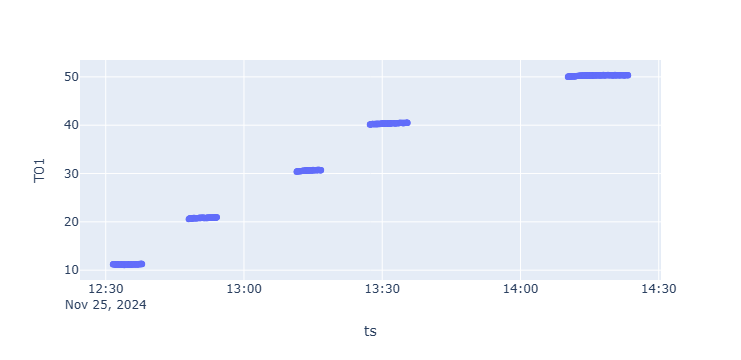

In [4]:
#| label: fig-calib-t01-serie
#| fig-cap: "Lecturas del sensor `T01` el 25 de noviembre de 2024, con `plotly.express`. Cinco escalones de unos minutos cada uno, de 10 a 50 °C, sin lecturas entre uno y otro."
#| fig-alt: "Puntos azules en cinco tramos horizontales escalonados entre las 12:30 y las 14:30, a 11, 21, 31, 40 y 50 grados."
fig = px.scatter(
    data_frame=T01,
    x=T01.index,
    y="T01"
)
fig.show()

## Seleccionar un tramo por hora con `between_time`

`between_time("12:32", "12:37")` devuelve las filas cuyo reloj, sin la fecha, cae entre esas
dos horas. Aquí se pide sólo su `.index` para ver qué estampas caen en el primer escalón: 98
lecturas, de las 12:36:57 hacia atrás porque el archivo está en orden descendente.

In [6]:
T01.Tref.between_time("12:32","12:37").index

DatetimeIndex(['2024-11-25 12:36:57.316000', '2024-11-25 12:36:54.283000',
               '2024-11-25 12:36:51.241000', '2024-11-25 12:36:48.203000',
               '2024-11-25 12:36:45.200000', '2024-11-25 12:36:42.128000',
               '2024-11-25 12:36:39.089000', '2024-11-25 12:36:36.052000',
               '2024-11-25 12:36:33.014000', '2024-11-25 12:36:29.980000',
               '2024-11-25 12:36:26.947000', '2024-11-25 12:36:23.898000',
               '2024-11-25 12:36:20.863000', '2024-11-25 12:36:17.823000',
               '2024-11-25 12:36:14.785000', '2024-11-25 12:36:11.760000',
               '2024-11-25 12:36:08.713000', '2024-11-25 12:36:05.673000',
               '2024-11-25 12:36:02.635000', '2024-11-25 12:35:59.598000',
               '2024-11-25 12:35:56.561000', '2024-11-25 12:35:53.525000',
               '2024-11-25 12:35:50.486000', '2024-11-25 12:35:47.452000',
               '2024-11-25 12:35:44.411000', '2024-11-25 12:35:41.375000',
               '2024-11-2

## Etiquetar cada escalón con su temperatura de referencia

Cinco asignaciones con `loc[filas, "Tref"] = valor`: las filas son el índice que devuelve
`between_time` para cada ventana y el valor es la temperatura de referencia de ese escalón. Las
ventanas se eligieron a mano mirando la figura y son más estrechas que el escalón completo,
para dejar fuera la transición. Quedan etiquetadas 98, 20, 34, 30 y 67 lecturas (249 en total);
el resto de la columna sigue en `NaN`.

In [10]:
T01.loc[T01.Tref.between_time("12:32","12:37").index,"Tref"] = 10 
T01.loc[T01.Tref.between_time("12:52","12:53").index,"Tref"] = 20 
T01.loc[T01.Tref.between_time("13:14:49","13:16:39").index,"Tref"] = 30 
T01.loc[T01.Tref.between_time("13:34:00","13:35:31").index,"Tref"] = 40 
T01.loc[T01.Tref.between_time("14:19:12","14:22:37").index,"Tref"] = 50 

## Referencia y sensor sobre el mismo eje de tiempo

`px.scatter` con una lista en `y` dibuja dos series y las nombra `wide_variable_0` (`Tref`) y
`wide_variable_1` (`T01`), porque recibió columnas sueltas y no un DataFrame con nombres. La
referencia es un segmento perfectamente horizontal en cada escalón y sólo existe dentro de las
ventanas; el sensor queda apenas por encima en todos, con más separación a 10 °C que a 50. El
error no es un desfase constante, por eso se ajusta una recta y no una resta.

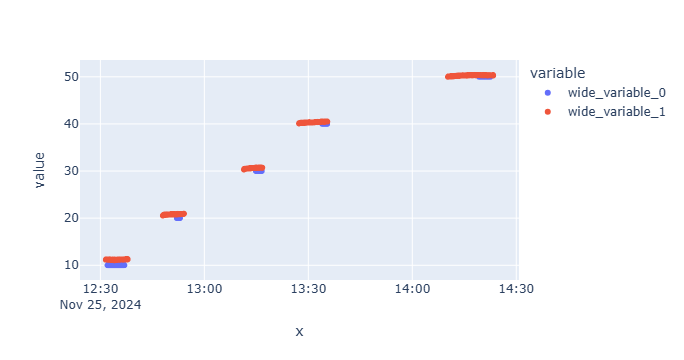

In [12]:
#| label: fig-calib-t01-tref
#| fig-cap: "Referencia (`wide_variable_0`) y sensor (`wide_variable_1`) sobre el mismo eje de tiempo, sólo dentro de las ventanas etiquetadas. El sensor lee por encima de la referencia en todos los escalones, más a 10 °C que a 50."
#| fig-alt: "Cinco pares de tramos horizontales; en cada escalón el tramo rojo del sensor queda apenas arriba del azul de la referencia, con más separación a 10 grados."
px.scatter(
    x=T01.index,
    y = [T01.Tref,T01.T01]
)

## Sensor contra referencia

Los mismos datos sin el tiempo: `x` es la lectura del sensor y `y` la referencia. plotly omite
las filas con `NaN`, así que las 249 lecturas etiquetadas se apilan en cinco puntos casi
alineados sobre una diagonal. Ésa es la curva de calibración de `T01`, y la recta que mejor
pasa por los cinco puntos es lo que se quiere ajustar.

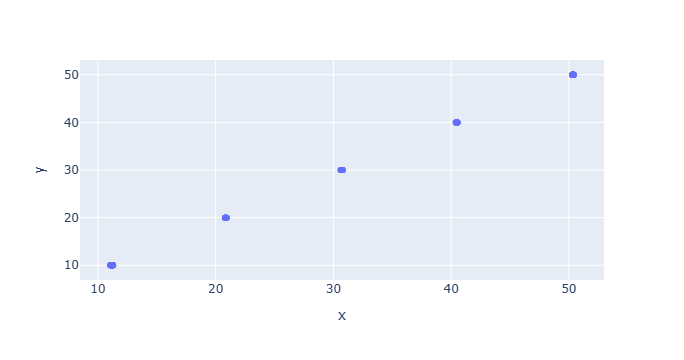

In [13]:
#| label: fig-calib-t01-vs-tref
#| fig-cap: "Temperatura de referencia contra lectura del sensor: las 249 lecturas etiquetadas se apilan en cinco puntos casi alineados. Es la curva de calibración de `T01`."
#| fig-alt: "Cinco puntos azules sobre una diagonal, de (11, 10) a (50, 50)."
px.scatter(
    x=T01.T01,
    y=T01.Tref
)

## Quitar las filas sin referencia

`dropna(inplace=True)` elimina las filas con `NaN` en cualquier columna: quedan las 249
lecturas etiquetadas. pandas 3 avisa con un `Pandas4Warning` que `inplace` desaparecerá; la
forma que sobrevive es `T01 = T01.dropna()`. Las cuentas de ejecución muestran que esta celda
(22) se corrió después de la última de la libreta (20): por eso aquélla todavía muestra los
`NaN`.

In [22]:
T01.dropna(inplace=True)

C:\Users\gbv\AppData\Local\Temp\ipykernel_13408\3385617778.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  T01.dropna(inplace=True)


## Primer intento de regresión con `scikit-learn`

`LinearRegression()` crea el modelo y `fit(X, y)` lo ajusta. `scikit-learn` espera `X` como una
matriz de *n muestras × m variables*; con una sola variable la forma correcta es `reshape(-1,
1)`, 249 filas y una columna. Aquí se escribió `reshape(1, -1)`, una fila y 249 columnas:
`scikit-learn` no protesta, pero entiende *una* muestra con 249 variables, y la "recta" que
devuelve no sirve para calibrar. La celda responde `LinearRegression()` como si todo estuviera
bien: el error está en la forma de los datos, no en el modelo. El ajuste correcto queda
pendiente.

In [25]:
model = LinearRegression()
model.fit(T01.T01.to_numpy().reshape(1, -1), T01.Tref.to_numpy().reshape(1, -1))


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](249, 249)","[[0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.], ..., [0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.], [0.,0.,0.,...,0.,0.,0.]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](249,)","[50.,50.,50.,...,10.,10.,10.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,249
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(0)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[0.]


`to_numpy()` convierte la columna en un arreglo de NumPy, que es lo que `fit` recibe. Se
ejecutó antes del `dropna` (cuenta 20), por eso el arreglo todavía tiene los `NaN` entre
escalones; después del `dropna` sólo quedan los cinco valores de referencia repetidos.

In [20]:
T01.Tref.to_numpy()

array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, 50., 50., 50.,
       50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50.,
       50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50.,
       50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50.,
       50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50.,
       50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50., nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, na